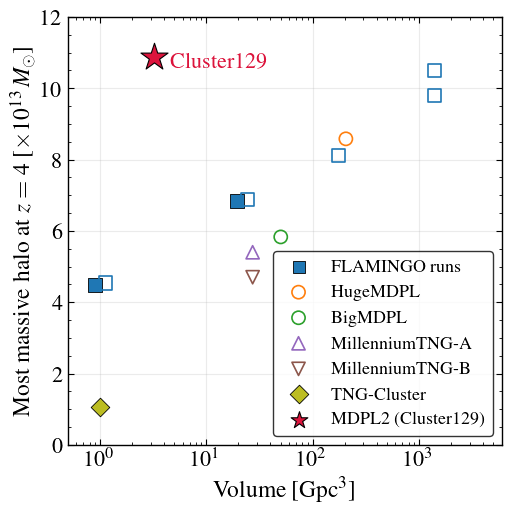

In [30]:
import matplotlib
import matplotlib.pyplot as plt
from set_style import set_style

# ---------------------------------------------------------------------------
# FLAMINGO: most massive halo (rank 1 in M200c) at z=4 per run,
# from flamingo_mmh_z4.txt.  run: (box side [Gpc], M200c [1e13 Msun], is_DMO)
# All volumes in this script are physical-unit comoving Gpc^3 (no h).
# ---------------------------------------------------------------------------
flamingo = {
    # 1 Gpc: only the most massive across all resolutions (both are m8)
    "L1_m8":         (1.0,  4.480,  False),
    "L1_m8_DMO":     (1.0,  4.536,  True),
    "L2p8_m9":       (2.8,  6.848,  False),
    "L2p8_m9_DMO":   (2.8,  6.880,  True),
    "L5p6_m10_DMO":  (5.6,  8.104,  True),
}
# L11p2: 11.2 Gpc box, two objects (masses from the paper table)
flamingo_L11p2 = (11.2**3, [10.5, 9.8], True)

# Other simulations: name: (volume [Gpc^3], [masses 1e13 Msun], marker, colour)
# Volumes converted from h^-1 units:
#   MultiDark (h = 0.6777): HugeMDPL 4.0, BigMDPL 2.5, MDPL2 1.0 h^-1 Gpc side
#   MTNG3000: 2040 h^-1 Mpc side (Hernandez-Aguayo et al. 2023), h = 0.6774
#   TNG-Cluster: 0.31 (h^-1 Gpc)^3, h = 0.6774
dmo_sims = {"HugeMDPL", "BigMDPL", "MillenniumTNG-A", "MillenniumTNG-B"}   # no full hydro: empty symbols
sims = {
    "HugeMDPL":        (205.62, [8.58], "o", "C1"),
    "BigMDPL":         (50.20,  [5.83], "o", "C2"),
    "MillenniumTNG-A": (27.31,  [5.4],  "^", "C4"),
    "MillenniumTNG-B": (27.31,  [4.7],  "v", "C5"),
    "TNG-Cluster":     (1.00,   [1.05], "D", "C8"),
}
mdpl2_vol, mdpl2_mass = 3.21, 10.87  # Cluster129 (GIZMO-Simba zoom-in of an MDPL2 halo)

FL_COL = "C0"

set_style('mnras')
fs = 17
fig, ax = plt.subplots(figsize=(5,5))

# FLAMINGO: filled = hydro, empty = DMO; one legend entry for all
fl_points = [(L**3, M, dmo) for L, M, dmo in flamingo.values()]
fl_points += [(flamingo_L11p2[0], M, True) for M in flamingo_L11p2[1]]
# where a box has both hydro and DMO, nudge them apart in (log) volume
hydro_vols = {v for v, _, d in fl_points if not d}
dmo_vols = {v for v, _, d in fl_points if d}
SHIFT = 1.12   # multiplicative offset on the log axis (display only)
for vol, M, dmo in fl_points:
    if vol in hydro_vols & dmo_vols:
        vol = vol * SHIFT if dmo else vol / SHIFT
    ax.scatter(vol, M, marker="s", s=90, linewidth=1.2 if dmo else 0.6,
               facecolor="none" if dmo else FL_COL,
               edgecolor=FL_COL if dmo else "k",
               zorder=4 if dmo else 3)   # empty symbols drawn on top so both stay visible
    
ax.scatter([], [], marker="s", s=70, color=FL_COL, edgecolor="k",
           linewidth=0.6, label="FLAMINGO runs")

for name, (vol, masses, mk, col) in sims.items():
    dmo = name in dmo_sims
    ax.scatter([vol] * len(masses), masses, marker=mk, s=90,
               facecolor="none" if dmo else col,
               edgecolor=col if dmo else "k",
               linewidth=1.2 if dmo else 0.6, label=name, zorder=3)

ax.scatter(mdpl2_vol, mdpl2_mass, marker="*", s=420, color="crimson",
           edgecolor="k", linewidth=0.8, zorder=5, label="MDPL2 (Cluster129)")
ax.annotate("Cluster129", (mdpl2_vol, mdpl2_mass), xytext=(12, -4),
            textcoords="offset points", fontsize=fs-1, fontweight="bold",
            color="crimson", va="center")

ax.set_xscale("log")
ax.set_xlim(0.5, 6000)
ax.set_ylim(0, 12)
ax.set_xlabel(r"Volume [${\rm Gpc}^3$]", fontsize=fs)
ax.set_ylabel(r"Most massive halo at $z=4$ [$\times10^{13}\,M_\odot$]", fontsize=fs)
ax.tick_params(which="major", direction="in", top=True, right=True, labelsize=fs-1,length=4)
ax.grid(alpha=0.25, zorder=0)
leg = ax.legend(fontsize=fs-4, frameon=True, loc="lower right")
leg.legend_handles[-1].set_sizes([160])  # shrink the star in the legend only

fig.savefig("volume_vs_mass.pdf")
fig.savefig("volume_vs_mass.png", dpi=200)
